# 18 — Scaled RAID complementarity test

This notebook is **standalone** and assumes a fresh kernel. It uses only persisted files and public model weights.

The small-panel experiment was ceiling-limited because WaveDetect was already near-perfect and each held-out fold contained only a handful of source pairs. Here we scale to **30 candidate sources per machine generator** and use source-level cross-fitting so every eligible source receives exactly one out-of-fold prediction per condition.

We compare:

\[
L_{256}
\]

as a single long-context loss / perplexity-equivalent baseline,

\[
U3 = (L_8-L_{32},\,L_8-L_{128},\,L_8-L_{256}),
\]

the paper's context-utility class,

\[
SL6=(L_8,L_{16},L_{32},L_{64},L_{128},L_{256}),
\]

and WaveDetect \(W\), plus:

\[
W+L_{256},\qquad W+U3,\qquad W+SL6.
\]

The key confirmatory comparison is:

\[
W+SL6 \quad \text{vs.}\quad W.
\]

Because WaveDetect is already saturated on RAID-like data, the question is not whether the gain is large; it is whether the **small residual gain is consistently positive when test-set quantization is reduced**.

Primary significance analysis uses source-level paired bootstrap intervals and an exact McNemar/binomial test on cross-fitted predictions.


## 1. Setup


In [1]:
from pathlib import Path
import sys, gc, time, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from scipy.stats import binomtest

cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "experiments" else cwd
DATA = ROOT/"data"
RESULTS = ROOT/"results"
FIGURES = ROOT/"figures"
EXTERNAL = DATA/"external"

for p in [DATA,RESULTS,FIGURES,EXTERNAL]:
    p.mkdir(parents=True,exist_ok=True)

RAID_CSV = Path.home()/".cache"/"raid"/"train.csv"
assert RAID_CSV.exists(), (
    f"Missing {RAID_CSV}. Download RAID train.csv once, then restart the kernel."
)

print("ROOT:",ROOT)
print("RAID CSV GB:",RAID_CSV.stat().st_size/1e9)


ROOT: ..
RAID CSV GB: 11.779491051


## 2. Build a larger deterministic complete machine panel

We stream RAID rather than loading the 11.8 GB CSV into RAM.

Candidate pool:
- `domain == "news"`
- machine-generated text only
- all 11 RAID attacks available
- 30 source generations per machine generator

Selection is deterministic by SHA-256 hash of the source ID. This makes the sample stable across reruns and naturally nested if `PER_MODEL` is later increased.


In [2]:
MACHINE_MODELS = [
    "chatgpt","cohere","cohere-chat","gpt2","gpt3","gpt4",
    "llama-chat","mistral","mistral-chat","mpt","mpt-chat",
]

ATTACKS = [
    "alternative_spelling",
    "article_deletion",
    "homoglyph",
    "insert_paragraphs",
    "number",
    "paraphrase",
    "perplexity_misspelling",
    "synonym",
    "upper_lower",
    "whitespace",
    "zero_width_space",
]

PER_MODEL = 30
PANEL_IDS_PATH = RESULTS/"raid_scaled_panel_ids.csv"

if PANEL_IDS_PATH.exists():
    selected = pd.read_csv(PANEL_IDS_PATH)
    selected_ids = selected["adv_source_id"].astype(str).tolist()
    print("loaded saved panel IDs:",len(selected_ids))
else:
    from collections import defaultdict
    attack_sets = defaultdict(set)
    source_model = {}

    usecols = ["adv_source_id","model","attack","domain"]

    for j,chunk in enumerate(pd.read_csv(
        RAID_CSV,usecols=usecols,chunksize=150_000
    )):
        chunk = chunk[
            chunk["domain"].eq("news")
            & chunk["model"].isin(MACHINE_MODELS)
            & ~chunk["attack"].eq("none")
        ]

        # vectorized collection per chunk
        for adv_id, model, attack in chunk[
            ["adv_source_id","model","attack"]
        ].itertuples(index=False,name=None):
            aid = str(adv_id)
            attack_sets[aid].add(str(attack))
            source_model[aid] = str(model)

        if j % 25 == 0:
            print("chunks:",j,"candidate sources:",len(attack_sets))

    complete = [
        sid for sid,a in attack_sets.items()
        if set(ATTACKS).issubset(a)
    ]

    by_model = defaultdict(list)
    for sid in complete:
        by_model[source_model[sid]].append(sid)

    rows=[]
    for model in sorted(by_model):
        ids=by_model[model]
        ids=sorted(
            ids,
            key=lambda s: hashlib.sha256(
                ("raid-scaled-v1::"+s).encode()
            ).hexdigest()
        )
        chosen=ids[:min(PER_MODEL,len(ids))]
        for sid in chosen:
            rows.append({"adv_source_id":sid,"model":model})

    selected=pd.DataFrame(rows)
    selected.to_csv(PANEL_IDS_PATH,index=False)
    selected_ids=selected["adv_source_id"].tolist()

print(selected["model"].value_counts().sort_index())
print("selected sources:",len(selected_ids))


chunks: 0 candidate sources: 0
chunks: 25 candidate sources: 60520
model
chatgpt         30
cohere          30
cohere-chat     30
gpt2            30
gpt3            30
gpt4            30
llama-chat      30
mistral         30
mistral-chat    30
mpt             30
mpt-chat        30
Name: count, dtype: int64
selected sources: 330


## 3. Recover exactly the selected machine variants and matched human sources

For each selected machine source, RAID's `source_id` identifies the matched human source. We first recover the 12 machine rows per selected source, then make a second streaming pass for only those human IDs.


In [3]:
RAW_PANEL_PATH = RESULTS/"raid_scaled_raw_panel.parquet"

if RAW_PANEL_PATH.exists():
    panel_raw=pd.read_parquet(RAW_PANEL_PATH)
    print("loaded raw panel:",panel_raw.shape)
else:
    wanted=set(map(str,selected_ids))
    usecols=[
        "id","adv_source_id","source_id","model","decoding",
        "repetition_penalty","attack","domain","generation",
    ]
    pieces=[]

    for j,chunk in enumerate(pd.read_csv(
        RAID_CSV,usecols=usecols,chunksize=150_000
    )):
        keep=chunk[
            chunk["adv_source_id"].astype(str).isin(wanted)
            & chunk["model"].isin(MACHINE_MODELS)
            & chunk["domain"].eq("news")
        ]
        if len(keep):
            pieces.append(keep.copy())
        if j%25==0:
            print("machine pass chunk",j)

    machine_raw=pd.concat(pieces,ignore_index=True).drop_duplicates("id")

    human_ids=set(machine_raw["source_id"].astype(str))
    hp=[]

    for j,chunk in enumerate(pd.read_csv(
        RAID_CSV,usecols=usecols,chunksize=150_000
    )):
        keep=chunk[
            chunk["id"].astype(str).isin(human_ids)
            & chunk["model"].eq("human")
            & chunk["attack"].eq("none")
        ]
        if len(keep):
            hp.append(keep.copy())
        if j%25==0:
            print("human pass chunk",j)

    human_raw=pd.concat(hp,ignore_index=True).drop_duplicates("id")

    machine_raw["row_role"]="machine"
    human_raw["row_role"]="human"
    panel_raw=pd.concat([machine_raw,human_raw],ignore_index=True)
    panel_raw.to_parquet(RAW_PANEL_PATH,index=False)

machine_raw=panel_raw[panel_raw["row_role"].eq("machine")].copy()
human_raw=panel_raw[panel_raw["row_role"].eq("human")].copy()

print("machine rows:",len(machine_raw))
print("machine parents:",machine_raw["adv_source_id"].nunique())
print("human rows:",len(human_raw))

coverage=pd.crosstab(
    machine_raw["adv_source_id"].astype(str),
    machine_raw["attack"].astype(str),
)

print("all selected machine parents have 12 variants:",
      bool((coverage==1).all().all()))
display(machine_raw.groupby("model")["adv_source_id"].nunique())


machine pass chunk 0
machine pass chunk 25
human pass chunk 0
human pass chunk 25
machine rows: 3960
machine parents: 330
human rows: 301
all selected machine parents have 12 variants: True


model
chatgpt         30
cohere          30
cohere-chat     30
gpt2            30
gpt3            30
gpt4            30
llama-chat      30
mistral         30
mistral-chat    30
mpt             30
mpt-chat        30
Name: adv_source_id, dtype: int64

## 4. Qwen SL6 scoring

We score both machine variants and matched human sources with the same frozen Qwen3-0.6B-Base scorer.

This implementation batches the up-to-eight target positions for each context length, reducing the number of forward passes per document from roughly 48 to 6.

Documents shorter than 257 scorer tokens are marked ineligible.


In [4]:
from transformers import AutoTokenizer, AutoModelForCausalLM

QWEN_ID="Qwen/Qwen3-0.6B-Base"
QWEN_CACHE=RESULTS/"raid_scaled_sl6_qwen06b.parquet"
K_VALUES=[8,16,32,64,128,256]
SL6_COLS=[f"L_{k}" for k in K_VALUES]

DEVICE="cuda" if torch.cuda.is_available() else "cpu"
DTYPE=torch.float16 if DEVICE=="cuda" else torch.float32

if QWEN_CACHE.exists():
    q_scores=pd.read_parquet(QWEN_CACHE)
else:
    q_scores=pd.DataFrame()

done=set(q_scores["id"].astype(str)) if len(q_scores) else set()

all_text=panel_raw[[
    "id","generation","row_role","model","attack",
    "adv_source_id","source_id"
]].drop_duplicates("id").copy()

pending=all_text[~all_text["id"].astype(str).isin(done)].copy()
print("Qwen cached:",len(done),"remaining:",len(pending))

if len(pending):
    tokenizer=AutoTokenizer.from_pretrained(QWEN_ID)
    qwen=AutoModelForCausalLM.from_pretrained(
        QWEN_ID,torch_dtype=DTYPE
    )
    qwen.eval().to(DEVICE)

    @torch.inference_mode()
    def score_doc(text):
        ids=tokenizer(
            str(text),
            add_special_tokens=False,
            truncation=True,
            max_length=384,
        )["input_ids"]

        if len(ids)<=256:
            return None

        last=len(ids)-1
        targets=np.unique(
            np.linspace(
                256,last,min(8,last-255)
            ).round().astype(int)
        )

        out={
            "n_tokens_scored":len(ids),
            "n_targets":len(targets),
        }

        for k in K_VALUES:
            # Every context at a fixed k has the same sequence length k+1.
            batch=torch.tensor(
                [ids[int(t)-k:int(t)+1] for t in targets],
                dtype=torch.long,
                device=DEVICE,
            )
            logits=qwen(input_ids=batch).logits
            pred=logits[:,-2,:].float()
            y=torch.tensor(
                [ids[int(t)] for t in targets],
                dtype=torch.long,
                device=DEVICE,
            )
            losses=torch.nn.functional.cross_entropy(
                pred,y,reduction="none"
            )
            out[f"L_{k}"]=float(losses.mean().item())

        return out

    records=q_scores.to_dict("records")
    t0=time.time()

    for i,r in enumerate(pending.itertuples(index=False),start=1):
        s=score_doc(r.generation)

        row={
            "id":r.id,
            "row_role":r.row_role,
            "model":r.model,
            "attack":r.attack,
            "adv_source_id":r.adv_source_id,
            "source_id":r.source_id,
        }
        if s is None:
            row.update({
                "n_tokens_scored":np.nan,
                "n_targets":np.nan,
                **{c:np.nan for c in SL6_COLS},
            })
        else:
            row.update(s)

        records.append(row)

        if i%25==0:
            pd.DataFrame(records).drop_duplicates(
                "id",keep="last"
            ).to_parquet(QWEN_CACHE,index=False)
            print(
                f"{i}/{len(pending)} new | "
                f"{(time.time()-t0)/60:.1f} min"
            )

    q_scores=pd.DataFrame(records).drop_duplicates("id",keep="last")
    q_scores.to_parquet(QWEN_CACHE,index=False)

    del qwen
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print("Qwen rows:",len(q_scores))
print("Qwen eligible:",q_scores[SL6_COLS].notna().all(axis=1).sum())


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Qwen cached: 0 remaining: 4261


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████| 310/310 [00:00<00:00, 3214.88it/s]


25/4261 new | 0.1 min
50/4261 new | 0.3 min
75/4261 new | 0.4 min
100/4261 new | 0.5 min
125/4261 new | 0.6 min
150/4261 new | 0.7 min
175/4261 new | 0.8 min
200/4261 new | 0.9 min
225/4261 new | 1.0 min
250/4261 new | 1.2 min
275/4261 new | 1.3 min
300/4261 new | 1.4 min
325/4261 new | 1.5 min
350/4261 new | 1.6 min
375/4261 new | 1.7 min
400/4261 new | 1.8 min
425/4261 new | 1.9 min
450/4261 new | 2.1 min
475/4261 new | 2.1 min
500/4261 new | 2.2 min
525/4261 new | 2.3 min
550/4261 new | 2.4 min
575/4261 new | 2.5 min
600/4261 new | 2.7 min
625/4261 new | 2.8 min
650/4261 new | 2.9 min
675/4261 new | 3.0 min
700/4261 new | 3.1 min
725/4261 new | 3.2 min
750/4261 new | 3.4 min
775/4261 new | 3.5 min
800/4261 new | 3.7 min
825/4261 new | 3.8 min
850/4261 new | 3.9 min
875/4261 new | 4.0 min
900/4261 new | 4.1 min
925/4261 new | 4.2 min
950/4261 new | 4.4 min
975/4261 new | 4.5 min
1000/4261 new | 4.6 min
1025/4261 new | 4.7 min
1050/4261 new | 4.8 min
1075/4261 new | 4.9 min
1100/4261 

## 5. WaveDetect scoring

Public model: `KaitongQin/WaveDetect`, pinned revision `d38df62`.

Scores are checkpointed and resumable. We convert the public `ai_score` probability to a clipped logit \(W\).


In [5]:
from huggingface_hub import snapshot_download
from tqdm.auto import tqdm

HF_REPO="KaitongQin/WaveDetect"
HF_REVISION="d38df62"
WAVE_DIR=EXTERNAL/"wavedetect_hf"
WAVE_CACHE=RESULTS/"raid_scaled_wavedetect.parquet"

if not (WAVE_DIR/"wavedetect_hf.py").exists():
    snapshot_download(
        repo_id=HF_REPO,
        revision=HF_REVISION,
        local_dir=str(WAVE_DIR),
    )

sys.path.insert(0,str(WAVE_DIR))
from wavedetect_hf import WaveDetectPredictor

wave_scores=pd.read_parquet(WAVE_CACHE) if WAVE_CACHE.exists() else pd.DataFrame()
done=set(wave_scores["id"].astype(str)) if len(wave_scores) else set()

pending=all_text[~all_text["id"].astype(str).isin(done)].copy()
print("Wave cached:",len(done),"remaining:",len(pending))

if len(pending):
    predictor=WaveDetectPredictor(
        model_dir=WAVE_DIR,
        device=DEVICE,
        max_length=1024,
    )

    rec=wave_scores.to_dict("records")

    for i,r in enumerate(
        tqdm(pending.itertuples(index=False),
             total=len(pending),
             desc="WaveDetect"),
        start=1,
    ):
        try:
            p=float(predictor.predict(str(r.generation))["ai_score"])
            err=None
        except Exception as exc:
            p=np.nan
            err=f"{type(exc).__name__}: {exc}"

        rec.append({
            "id":r.id,
            "wave_ai_score":p,
            "wave_error":err,
        })

        if i%50==0:
            pd.DataFrame(rec).drop_duplicates(
                "id",keep="last"
            ).to_parquet(WAVE_CACHE,index=False)

    wave_scores=pd.DataFrame(rec).drop_duplicates("id",keep="last")
    wave_scores.to_parquet(WAVE_CACHE,index=False)

    del predictor
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

EPS=1e-6
wave_scores["W"]=np.log(
    wave_scores["wave_ai_score"].clip(EPS,1-EPS)
    /(1-wave_scores["wave_ai_score"].clip(EPS,1-EPS))
)

print("Wave rows:",len(wave_scores))
print("Wave successful:",wave_scores["W"].notna().sum())


Wave cached: 0 remaining: 4261


WaveDetect: 100%|███████████████████████████████████████████████████████████████████████████████████| 4261/4261 [02:33<00:00, 27.70it/s]


Wave rows: 4261
Wave successful: 4261


## 6. Assemble feature table and derive \(U3\)

\(L_{256}\) is the single-loss/perplexity baseline.

The original context-utility class is represented as:

\[
U(32)=L_8-L_{32},
\quad
U(128)=L_8-L_{128},
\quad
U(256)=L_8-L_{256}.
\]

SL6 retains the sparse multiscale loss curve.


In [10]:
feat = (
    q_scores
    .merge(
        wave_scores[["id", "W"]],
        on="id",
        how="left",
        validate="one_to_one",
    )
)

feat["U_32"] = feat["L_8"] - feat["L_32"]
feat["U_128"] = feat["L_8"] - feat["L_128"]
feat["U_256"] = feat["L_8"] - feat["L_256"]

U3_COLS = ["U_32", "U_128", "U_256"]

machine_f = feat[
    feat["row_role"].eq("machine")
].copy()

human_f = feat[
    feat["row_role"].eq("human")
].copy()


# ============================================================
# IMPORTANT:
# RAID can contain multiple machine generations derived from
# the same human source_id.
#
# Keep exactly ONE complete machine parent per human source.
# Selection uses only IDs, never scores/features.
# ============================================================

clean_parents = (
    machine_f[
        machine_f["attack"].eq("none")
    ][
        [
            "adv_source_id",
            "source_id",
            "model",
        ]
    ]
    .drop_duplicates()
    .copy()
)

clean_parents["selection_hash"] = (
    clean_parents["adv_source_id"]
    .astype(str)
    .map(
        lambda s: hashlib.sha256(
            ("raid-unique-human-v1::" + s).encode()
        ).hexdigest()
    )
)

clean_parents = (
    clean_parents
    .sort_values(
        ["source_id", "selection_hash"]
    )
    .drop_duplicates(
        "source_id",
        keep="first",
    )
)

kept_parent_ids = set(
    clean_parents["adv_source_id"].astype(str)
)

machine_f = machine_f[
    machine_f["adv_source_id"]
    .astype(str)
    .isin(kept_parent_ids)
].copy()


# After deterministic deduplication, source_id is now unique
# across machine parents and can safely be the split/pair ID.
machine_f["prompt_id"] = (
    machine_f["source_id"].astype(str)
)

human_f["prompt_id"] = (
    human_f["id"].astype(str)
)


FEATURE_SETS = {
    "L256": ["L_256"],
    "U3": U3_COLS,
    "SL6": SL6_COLS,
    "W+L256": ["W", "L_256"],
    "W+U3": ["W"] + U3_COLS,
    "W+SL6": ["W"] + SL6_COLS,
}

ALL_REQUIRED = SL6_COLS + ["W"]


print("machine features:", machine_f.shape)
print("human features:", human_f.shape)

print(
    "unique machine human-sources:",
    machine_f["prompt_id"].nunique()
)

print(
    "unique human negatives:",
    human_f["prompt_id"].nunique()
)

print("\nRETAINED CLEAN GENERATIONS BY MODEL")
display(
    machine_f[
        machine_f["attack"].eq("none")
    ]
    .groupby("model")["prompt_id"]
    .nunique()
)

machine features: (3612, 19)
human features: (301, 19)
unique machine human-sources: 301
unique human negatives: 301

RETAINED CLEAN GENERATIONS BY MODEL


model
chatgpt         27
cohere          28
cohere-chat     26
gpt2            29
gpt3            28
gpt4            24
llama-chat      29
mistral         25
mistral-chat    27
mpt             30
mpt-chat        28
Name: prompt_id, dtype: int64

## 7. Strict global common-support panel

For the confirmatory experiment, we use only source IDs for which all of the following are available:

- matched human SL6 + WaveDetect;
- clean machine SL6 + WaveDetect;
- **all 11 attacked machine variants** SL6 + WaveDetect.

This yields one identical source panel across every attack and every method.


In [11]:
h_ok=set(
    human_f[
        human_f[ALL_REQUIRED].notna().all(axis=1)
    ]["prompt_id"]
)

clean_ok=set(
    machine_f[
        machine_f["attack"].eq("none")
        & machine_f[ALL_REQUIRED].notna().all(axis=1)
    ]["prompt_id"]
)

attack_ok={}
for a in ATTACKS:
    attack_ok[a]=set(
        machine_f[
            machine_f["attack"].eq(a)
            & machine_f[ALL_REQUIRED].notna().all(axis=1)
        ]["prompt_id"]
    )

common=set(h_ok)&set(clean_ok)
for a in ATTACKS:
    common &= attack_ok[a]

COMMON_IDS=np.array(sorted(common))

print("GLOBAL COMMON-SUPPORT SOURCES:",len(COMMON_IDS))

model_balance=(
    machine_f[
        machine_f["attack"].eq("none")
        & machine_f["prompt_id"].isin(COMMON_IDS)
    ]
    .groupby("model")["prompt_id"].nunique()
)

display(model_balance)
assert len(COMMON_IDS)>=50, "Too few global common-support sources for the scaled test."


GLOBAL COMMON-SUPPORT SOURCES: 153


model
chatgpt         19
cohere          20
cohere-chat     11
gpt2            13
gpt3             7
gpt4            20
llama-chat      24
mistral         10
mistral-chat     9
mpt             16
mpt-chat         4
Name: prompt_id, dtype: int64

## 8. Five-fold source-level cross-fitting

Each source appears in the test set exactly once.

For every outer fold:

1. learned methods are trained only on **clean** machine versus matched human texts from the other folds;
2. regularization is chosen by inner source-level CV on clean training data only;
3. each detector threshold is calibrated from training-human scores to target 5% FPR;
4. the frozen model and threshold are evaluated on held-out humans plus:
   - held-out clean machine text;
   - each held-out RAID attack.

WaveDetect itself is never retrained; only its 5%-FPR threshold is calibrated.

This produces one out-of-fold prediction per source, per condition, per method.


In [12]:
C_GRID = [0.01, 0.1, 1.0, 10.0]
N_FOLDS = 5
FOLD_SEED = 1801


def make_clf(C):
    return Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(
            C=C,
            class_weight="balanced",
            solver="lbfgs",
            max_iter=5000,
            random_state=0,
        )),
    ])


def finite_rows(df, cols):
    """
    Keep only rows whose requested features are all finite.
    """
    out = df.copy()

    vals = out[cols].to_numpy(dtype=float)
    mask = np.isfinite(vals).all(axis=1)

    return out.loc[mask].copy()


def clean_train(ids, cols):
    m = machine_f[
        machine_f["attack"].eq("none")
        & machine_f["prompt_id"].isin(ids)
    ][["prompt_id"] + cols].copy()

    h = human_f[
        human_f["prompt_id"].isin(ids)
    ][["prompt_id"] + cols].copy()

    m = finite_rows(m, cols)
    h = finite_rows(h, cols)

    m["label"] = 1
    h["label"] = 0

    out = pd.concat(
        [m, h],
        ignore_index=True,
    )

    return out


def choose_C(df, cols, seed):
    df = finite_rows(df, cols)

    ids = np.array(
        sorted(df["prompt_id"].unique())
    )

    rng = np.random.default_rng(seed)
    ids = rng.permutation(ids)

    folds = np.array_split(
        ids,
        min(4, len(ids)),
    )

    vals = []

    for C in C_GRID:
        auc = []

        for va_ids in folds:
            va = set(va_ids)

            tr = df[
                ~df["prompt_id"].isin(va)
            ].copy()

            vv = df[
                df["prompt_id"].isin(va)
            ].copy()

            tr = finite_rows(tr, cols)
            vv = finite_rows(vv, cols)

            if (
                len(tr) == 0
                or len(vv) == 0
                or tr["label"].nunique() < 2
                or vv["label"].nunique() < 2
            ):
                continue

            clf = make_clf(C)

            clf.fit(
                tr[cols],
                tr["label"],
            )

            s = clf.predict_proba(
                vv[cols]
            )[:, 1]

            auc.append(
                roc_auc_score(
                    vv["label"],
                    s,
                )
            )

        vals.append((
            np.mean(auc) if len(auc) else -np.inf,
            C,
        ))

    vals.sort(
        key=lambda z: (-z[0], z[1])
    )

    return vals[0][1]


def fpr5_threshold(human_scores):
    x = np.asarray(
        human_scores,
        dtype=float,
    )

    x = x[np.isfinite(x)]

    assert len(x) > 0

    return float(
        np.quantile(
            x,
            0.95,
            method="higher",
        )
    )


# ------------------------------------------------------------
# Pre-flight diagnostic
# ------------------------------------------------------------

print("COMMON SOURCES:", len(COMMON_IDS))

for method, cols in FEATURE_SETS.items():

    tr = clean_train(
        set(COMMON_IDS),
        cols,
    )

    X = tr[cols].to_numpy(dtype=float)

    print(
        f"{method:8s} | "
        f"rows={len(tr):4d} | "
        f"finite={np.isfinite(X).all()} | "
        f"nan={np.isnan(X).sum()} | "
        f"inf={np.isinf(X).sum()}"
    )


# ------------------------------------------------------------
# Outer cross-fitting
# ------------------------------------------------------------

rng = np.random.default_rng(FOLD_SEED)

shuffled = rng.permutation(
    COMMON_IDS
)

folds = np.array_split(
    shuffled,
    N_FOLDS,
)

METHODS = [
    "WaveDetect"
] + list(FEATURE_SETS.keys())

CONDITIONS = [
    "none"
] + ATTACKS

pred_rows = []


for fold_idx, test_arr in enumerate(folds):

    test_ids = set(test_arr)

    train_ids = (
        set(COMMON_IDS)
        - test_ids
    )

    print(
        "\nfold",
        fold_idx + 1,
        "| train",
        len(train_ids),
        "| test",
        len(test_ids),
    )

    # --------------------------------------------------------
    # WaveDetect threshold
    # --------------------------------------------------------

    train_h = human_f[
        human_f["prompt_id"].isin(
            train_ids
        )
    ].copy()

    train_h = finite_rows(
        train_h,
        ["W"],
    )

    thr_w = fpr5_threshold(
        train_h["W"]
    )

    # --------------------------------------------------------
    # Learned detectors:
    # fit ONCE per fold using clean text only.
    # --------------------------------------------------------

    fitted = {}

    for method, cols in FEATURE_SETS.items():

        tr = clean_train(
            train_ids,
            cols,
        )

        assert (
            np.isfinite(
                tr[cols].to_numpy(float)
            ).all()
        ), f"nonfinite training values: {method}"

        C = choose_C(
            tr,
            cols,
            18010 + fold_idx,
        )

        clf = make_clf(C)

        clf.fit(
            tr[cols],
            tr["label"],
        )

        train_h_method = tr[
            tr["label"].eq(0)
        ]

        hscore = clf.predict_proba(
            train_h_method[cols]
        )[:, 1]

        thr = fpr5_threshold(
            hscore
        )

        fitted[method] = (
            clf,
            thr,
            C,
        )

    # --------------------------------------------------------
    # Evaluate every condition.
    # --------------------------------------------------------

    for condition in CONDITIONS:

        h = human_f[
            human_f["prompt_id"].isin(
                test_ids
            )
        ].copy()

        m = machine_f[
            machine_f["prompt_id"].isin(
                test_ids
            )
            & machine_f["attack"].eq(
                condition
            )
        ].copy()

        assert len(h) == len(test_ids), (
            condition,
            "human",
            len(h),
            len(test_ids),
        )

        assert len(m) == len(test_ids), (
            condition,
            "machine",
            len(m),
            len(test_ids),
        )

        # ----------------------------------------------------
        # WaveDetect
        # ----------------------------------------------------

        hw = finite_rows(h, ["W"])
        mw = finite_rows(m, ["W"])

        assert len(hw) == len(h)
        assert len(mw) == len(m)

        for r in hw.itertuples(
            index=False
        ):
            pred_rows.append({
                "fold": fold_idx,
                "prompt_id": r.prompt_id,
                "condition": condition,
                "method": "WaveDetect",
                "label": 0,
                "score": float(r.W),
                "threshold": thr_w,
                "pred": int(
                    r.W >= thr_w
                ),
            })

        for r in mw.itertuples(
            index=False
        ):
            pred_rows.append({
                "fold": fold_idx,
                "prompt_id": r.prompt_id,
                "condition": condition,
                "method": "WaveDetect",
                "label": 1,
                "score": float(r.W),
                "threshold": thr_w,
                "pred": int(
                    r.W >= thr_w
                ),
            })

        # ----------------------------------------------------
        # Learned methods
        # ----------------------------------------------------

        for method, (
            clf,
            thr,
            C,
        ) in fitted.items():

            cols = FEATURE_SETS[
                method
            ]

            hh = finite_rows(
                h,
                cols,
            )

            mm = finite_rows(
                m,
                cols,
            )

            assert len(hh) == len(h), (
                condition,
                method,
                "human lost",
                len(h) - len(hh),
            )

            assert len(mm) == len(m), (
                condition,
                method,
                "machine lost",
                len(m) - len(mm),
            )

            hs = clf.predict_proba(
                hh[cols]
            )[:, 1]

            ms = clf.predict_proba(
                mm[cols]
            )[:, 1]

            for pid, s in zip(
                hh["prompt_id"],
                hs,
            ):
                pred_rows.append({
                    "fold": fold_idx,
                    "prompt_id": pid,
                    "condition": condition,
                    "method": method,
                    "label": 0,
                    "score": float(s),
                    "threshold": thr,
                    "pred": int(
                        s >= thr
                    ),
                })

            for pid, s in zip(
                mm["prompt_id"],
                ms,
            ):
                pred_rows.append({
                    "fold": fold_idx,
                    "prompt_id": pid,
                    "condition": condition,
                    "method": method,
                    "label": 1,
                    "score": float(s),
                    "threshold": thr,
                    "pred": int(
                        s >= thr
                    ),
                })


pred = pd.DataFrame(
    pred_rows
)

pred["correct"] = (
    pred["pred"]
    == pred["label"]
).astype(int)

PRED_PATH = (
    RESULTS
    / "raid_scaled_oof_predictions.parquet"
)

pred.to_parquet(
    PRED_PATH,
    index=False,
)

print("\nOOF rows:", len(pred))

print(
    "expected:",
    len(COMMON_IDS)
    * 2
    * len(CONDITIONS)
    * len(METHODS)
)

display(pred.head())

COMMON SOURCES: 153
L256     | rows= 306 | finite=True | nan=0 | inf=0
U3       | rows= 306 | finite=True | nan=0 | inf=0
SL6      | rows= 306 | finite=True | nan=0 | inf=0
W+L256   | rows= 306 | finite=True | nan=0 | inf=0
W+U3     | rows= 306 | finite=True | nan=0 | inf=0
W+SL6    | rows= 306 | finite=True | nan=0 | inf=0

fold 1 | train 122 | test 31

fold 2 | train 122 | test 31

fold 3 | train 122 | test 31

fold 4 | train 123 | test 30

fold 5 | train 123 | test 30

OOF rows: 25704
expected: 25704


,fold,prompt_id,condition,method,label,score,threshold,pred,correct
0,0,ec3c57f1-e6c4-46fe-8ddb-3023424ac689,none,WaveDetect,0,-4.431477,-2.855772,0,1
1,0,9500c2e6-99ac-4795-ba4c-8386c6f2d1bf,none,WaveDetect,0,-5.021804,-2.855772,0,1
2,0,4610cbfb-e2c3-42a5-8158-ff1d60dadf11,none,WaveDetect,0,-2.995319,-2.855772,0,1
3,0,22aaa2ba-e8c6-4c02-ac8a-cbd1eb6fdd55,none,WaveDetect,0,-4.026790,-2.855772,0,1
4,0,5a07b60c-5f03-45f7-9bed-32d68db9df3d,none,WaveDetect,0,-3.831129,-2.855772,0,1


## 9. Cross-fitted RAID-style accuracy table

Because every common-support source appears exactly once out-of-fold, this is not an average of highly overlapping repeated test sets.

Each cell is out-of-fold accuracy at the detector's training-human-calibrated 5% FPR threshold.


In [13]:
metric_rows=[]

for (condition,method),g in pred.groupby(["condition","method"]):
    y=g["label"].to_numpy()
    s=g["score"].to_numpy()
    p=g["pred"].to_numpy()

    human=y==0
    machine_mask=y==1

    metric_rows.append({
        "condition":condition,
        "method":method,
        "n_sources":g["prompt_id"].nunique(),
        "accuracy":float((p==y).mean()),
        "tpr":float(p[machine_mask].mean()),
        "fpr":float(p[human].mean()),
        "auroc":roc_auc_score(y,s),
    })

metrics=pd.DataFrame(metric_rows)

display(
    metrics.pivot(
        index="method",
        columns="condition",
        values="accuracy",
    )
)

metrics.to_csv(
    RESULTS/"raid_scaled_metrics.csv",
    index=False,
)


condition,alternative_spelling,article_deletion,homoglyph,insert_paragraphs,none,number,paraphrase,perplexity_misspelling,synonym,upper_lower,whitespace,zero_width_space
method,,,,,,,,,,,,
L256,0.598039,0.571895,0.500000,0.575163,0.588235,0.581699,0.532680,0.588235,0.522876,0.552288,0.542484,0.875817
SL6,0.584967,0.575163,0.496732,0.562092,0.594771,0.588235,0.539216,0.581699,0.522876,0.545752,0.542484,0.885621
U3,0.535948,0.516340,0.513072,0.532680,0.532680,0.532680,0.532680,0.532680,0.516340,0.532680,0.594771,0.496732
W+L256,0.970588,0.973856,0.941176,0.931373,0.967320,0.970588,0.849673,0.973856,0.970588,0.970588,0.964052,0.941176
W+SL6,0.973856,0.977124,0.941176,0.941176,0.970588,0.970588,0.843137,0.977124,0.973856,0.973856,0.967320,0.947712
W+U3,0.967320,0.964052,0.931373,0.931373,0.964052,0.964052,0.852941,0.970588,0.960784,0.964052,0.960784,0.944444
WaveDetect,0.967320,0.967320,0.937908,0.934641,0.967320,0.967320,0.862745,0.967320,0.964052,0.964052,0.957516,0.950980


## 10. Confirmatory paired significance: \(W+SL6\) vs \(W\)

For each condition and source, define source-level accuracy as the mean correctness over its matched human and machine example:

\[
A_i=\frac{C_{i,\mathrm{human}}+C_{i,\mathrm{machine}}}{2}.
\]

Then:

\[
D_i=A_i(W+SL6)-A_i(W).
\]

We report:
- mean source-level gain;
- 95% source bootstrap CI;
- fraction of sources improved / worsened;
- exact two-sided binomial test among non-tied sources.

This directly tests whether positive changes outweigh negative changes without treating repeated CV folds as independent observations.


In [14]:
def source_accuracy(df,method,condition):
    g=df[
        df["method"].eq(method)
        & df["condition"].eq(condition)
    ]
    return g.groupby("prompt_id")["correct"].mean()

def boot_mean_ci(x,n_boot=50000,seed=1818):
    x=np.asarray(x,float)
    rng=np.random.default_rng(seed)
    idx=rng.integers(0,len(x),size=(n_boot,len(x)))
    means=x[idx].mean(axis=1)
    return np.quantile(means,[.025,.975])

sig_rows=[]

for condition in CONDITIONS:
    w=source_accuracy(pred,"WaveDetect",condition)
    ws=source_accuracy(pred,"W+SL6",condition)

    both=pd.concat([w.rename("W"),ws.rename("WSL")],axis=1).dropna()
    d=(both["WSL"]-both["W"]).to_numpy()

    lo,hi=boot_mean_ci(d,seed=1818+CONDITIONS.index(condition))

    pos=int((d>0).sum())
    neg=int((d<0).sum())
    ties=int((d==0).sum())

    pval=(
        binomtest(pos,pos+neg,p=.5,alternative="two-sided").pvalue
        if pos+neg>0 else 1.0
    )

    sig_rows.append({
        "condition":condition,
        "n_sources":len(d),
        "mean_gain":d.mean(),
        "median_gain":np.median(d),
        "ci95_lo":lo,
        "ci95_hi":hi,
        "positive_sources":pos,
        "negative_sources":neg,
        "ties":ties,
        "positive_fraction_nonties":pos/(pos+neg) if pos+neg else np.nan,
        "exact_binom_p":pval,
    })

sig=pd.DataFrame(sig_rows)
display(sig)

sig.to_csv(
    RESULTS/"raid_scaled_wsl6_vs_w_significance.csv",
    index=False,
)


,condition,n_sources,mean_gain,median_gain,ci95_lo,ci95_hi,positive_sources,negative_sources,ties,positive_fraction_nonties,exact_binom_p
0,none,153,0.003268,0.0,-0.016340,0.022876,5,4,144,0.555556,1.000000
1,alternative_spelling,153,0.006536,0.0,-0.009804,0.026144,5,3,145,0.625000,0.726562
2,article_deletion,153,0.009804,0.0,-0.006536,0.026144,5,2,146,0.714286,0.453125
3,homoglyph,153,0.003268,0.0,-0.016340,0.022876,6,5,142,0.545455,1.000000
4,insert_paragraphs,153,0.006536,0.0,-0.013072,0.026144,6,4,143,0.600000,0.753906
5,number,153,0.003268,0.0,-0.016340,0.022876,5,4,144,0.555556,1.000000
6,paraphrase,153,-0.019608,0.0,-0.049020,0.009804,7,12,134,0.368421,0.359283
7,perplexity_misspelling,153,0.009804,0.0,-0.006536,0.026144,5,2,146,0.714286,0.453125
8,synonym,153,0.009804,0.0,-0.006536,0.026144,5,2,146,0.714286,0.453125
9,upper_lower,153,0.009804,0.0,-0.006536,0.026144,5,2,146,0.714286,0.453125


## 11. Also test \(W+U3\), \(W+L_{256}\), and solo feature hierarchy

These are secondary comparisons.

The desired scientific distinction is not "every context feature beats perplexity everywhere." Instead we test whether:

1. a single \(L_{256}\) loss is a weak detector baseline;
2. context-relative \(U3\) improves over that baseline;
3. sparse multiscale SL6 retains additional useful structure;
4. only the multiscale/context-relative representations provide residual value once WaveDetect is already near saturation.


In [15]:
def paired_source_test(method_a,method_b,condition):
    a=source_accuracy(pred,method_a,condition)
    b=source_accuracy(pred,method_b,condition)
    both=pd.concat([a.rename("a"),b.rename("b")],axis=1).dropna()
    d=(both["a"]-both["b"]).to_numpy()

    lo,hi=boot_mean_ci(
        d,
        seed=1900+CONDITIONS.index(condition)
    )
    pos=int((d>0).sum())
    neg=int((d<0).sum())

    return {
        "condition":condition,
        "comparison":f"{method_a} vs {method_b}",
        "n_sources":len(d),
        "mean_gain":d.mean(),
        "ci95_lo":lo,
        "ci95_hi":hi,
        "positive":pos,
        "negative":neg,
        "ties":int((d==0).sum()),
        "binom_p":(
            binomtest(pos,pos+neg,p=.5).pvalue
            if pos+neg else 1.0
        ),
    }

comparisons=[
    ("U3","L256"),
    ("SL6","L256"),
    ("SL6","U3"),
    ("W+L256","WaveDetect"),
    ("W+U3","WaveDetect"),
    ("W+SL6","WaveDetect"),
]

comp_rows=[]

for a,b in comparisons:
    for c in CONDITIONS:
        comp_rows.append(paired_source_test(a,b,c))

comp=pd.DataFrame(comp_rows)

display(
    comp[
        comp["comparison"].isin([
            "U3 vs L256",
            "SL6 vs L256",
            "W+U3 vs WaveDetect",
            "W+SL6 vs WaveDetect",
        ])
    ]
)

comp.to_csv(
    RESULTS/"raid_scaled_pairwise_tests.csv",
    index=False,
)


,condition,comparison,n_sources,mean_gain,ci95_lo,ci95_hi,positive,negative,ties,binom_p
0,none,U3 vs L256,153,-0.055556,-0.098039,-0.013072,14,29,110,3.153950e-02
1,alternative_spelling,U3 vs L256,153,-0.062092,-0.111111,-0.013072,17,33,103,3.283914e-02
2,article_deletion,U3 vs L256,153,-0.055556,-0.101307,-0.009804,15,30,108,3.569780e-02
3,homoglyph,U3 vs L256,153,0.013072,-0.026144,0.049020,18,12,123,3.615946e-01
4,insert_paragraphs,U3 vs L256,153,-0.042484,-0.088235,0.000000,14,26,113,8.069047e-02
5,number,U3 vs L256,153,-0.049020,-0.091503,-0.006536,14,28,111,4.355852e-02
6,paraphrase,U3 vs L256,153,0.000000,-0.039216,0.035948,16,15,122,1.000000e+00
7,perplexity_misspelling,U3 vs L256,153,-0.055556,-0.101307,-0.013072,12,28,113,1.658900e-02
8,synonym,U3 vs L256,153,-0.006536,-0.042484,0.029412,15,16,122,1.000000e+00
9,upper_lower,U3 vs L256,153,-0.019608,-0.062092,0.022876,17,23,113,4.295905e-01


## 12. RAID Table 6 comparison

The published numbers below are transcribed from RAID Table 6.

Absolute cross-paper comparisons remain contextual because our evaluation is a controlled news-only matched subset. The within-our-subset comparisons and paired significance tests above are the inferential results.


In [16]:
raid_ref=pd.DataFrame({
    "None":[56.7,70.9,62.6,79.6,66.5,85.0],
    "Paraphrase":[72.9,67.3,47.2,80.3,64.0,96.7],
    "Synonym":[79.4,67.5,31.2,43.5,61.0,96.5],
    "Misspelling":[39.5,69.5,59.8,78.0,65.1,78.6],
    "Homoglyph":[21.3,59.3,24.3,37.7,66.2,9.3],
    "Whitespace":[40.1,66.1,45.8,70.1,66.2,84.9],
    "Delete Articles":[33.2,67.9,52.1,74.3,61.0,71.4],
},index=[
    "R-L GPT2","RADAR","GLTR","Binoculars","GPTZero","Originality"
])

map_cond={
    "None":"none",
    "Paraphrase":"paraphrase",
    "Synonym":"synonym",
    "Misspelling":"perplexity_misspelling",
    "Homoglyph":"homoglyph",
    "Whitespace":"whitespace",
    "Delete Articles":"article_deletion",
}

ours=metrics.pivot(
    index="method",columns="condition",values="accuracy"
)*100

ours_ref=pd.DataFrame(index=ours.index)
for label,c in map_cond.items():
    ours_ref[label]=ours[c]

combined=pd.concat([raid_ref,ours_ref])
display(combined.round(1))

combined.to_csv(
    RESULTS/"raid_scaled_table6_side_by_side.csv"
)


,None,Paraphrase,Synonym,Misspelling,Homoglyph,Whitespace,Delete Articles
R-L GPT2,56.7,72.9,79.4,39.5,21.3,40.1,33.2
RADAR,70.9,67.3,67.5,69.5,59.3,66.1,67.9
GLTR,62.6,47.2,31.2,59.8,24.3,45.8,52.1
Binoculars,79.6,80.3,43.5,78.0,37.7,70.1,74.3
GPTZero,66.5,64.0,61.0,65.1,66.2,66.2,61.0
Originality,85.0,96.7,96.5,78.6,9.3,84.9,71.4
L256,58.8,53.3,52.3,58.8,50.0,54.2,57.2
SL6,59.5,53.9,52.3,58.2,49.7,54.2,57.5
U3,53.3,53.3,51.6,53.3,51.3,59.5,51.6
W+L256,96.7,85.0,97.1,97.4,94.1,96.4,97.4


## 13. Figures


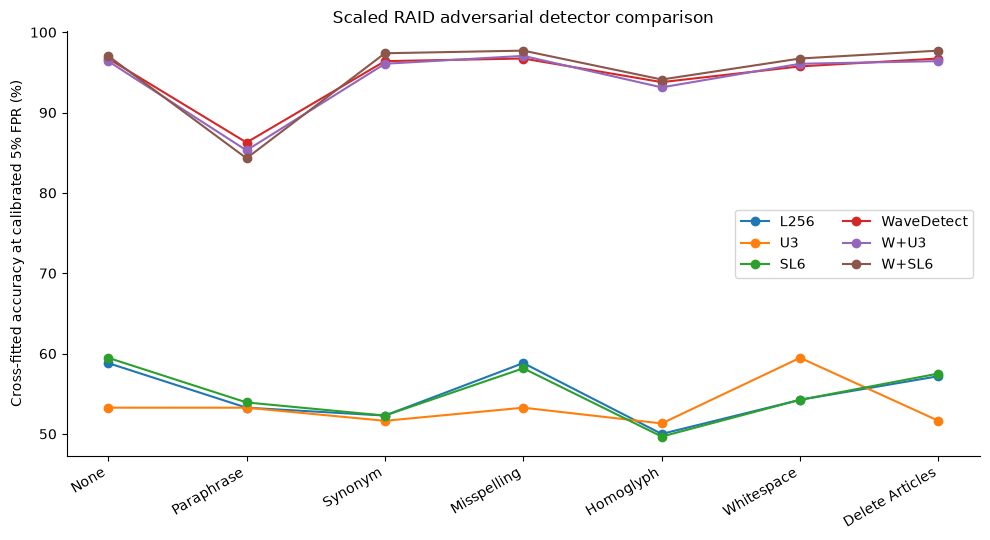

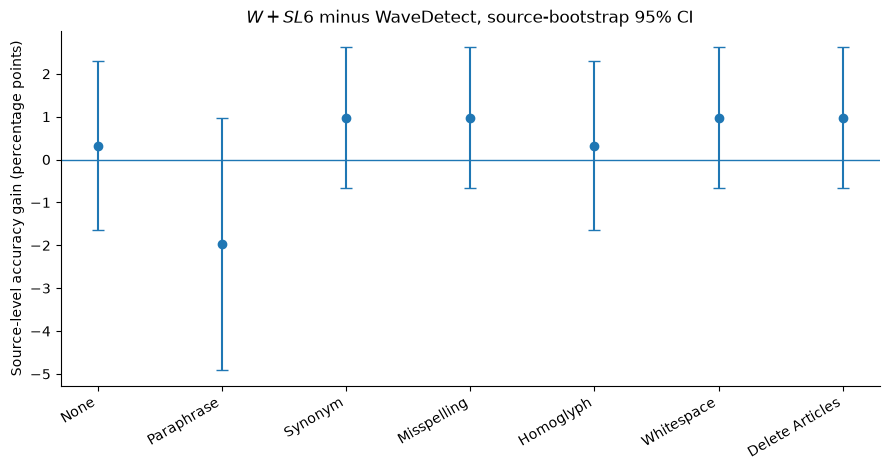

In [17]:
show_methods=[
    "L256","U3","SL6",
    "WaveDetect","W+U3","W+SL6",
]
show_conditions=[
    "none","paraphrase","synonym",
    "perplexity_misspelling","homoglyph",
    "whitespace","article_deletion",
]
labels=[
    "None","Paraphrase","Synonym",
    "Misspelling","Homoglyph",
    "Whitespace","Delete Articles",
]

p=metrics[
    metrics["method"].isin(show_methods)
    & metrics["condition"].isin(show_conditions)
].pivot(index="method",columns="condition",values="accuracy")

fig,ax=plt.subplots(figsize=(10,5.5))
x=np.arange(len(show_conditions))

for method in show_methods:
    ax.plot(
        x,
        100*p.loc[method,show_conditions].to_numpy(),
        marker="o",
        label=method,
    )

ax.set_xticks(x)
ax.set_xticklabels(labels,rotation=30,ha="right")
ax.set_ylabel("Cross-fitted accuracy at calibrated 5% FPR (%)")
ax.set_title("Scaled RAID adversarial detector comparison")
ax.legend(ncol=2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES/"raid_scaled_detector_comparison.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"raid_scaled_detector_comparison.png",dpi=200,bbox_inches="tight")
plt.show()

# W+SL6 source-level gain with CI.
sg=sig[sig["condition"].isin(show_conditions)].set_index("condition").loc[show_conditions]

fig,ax=plt.subplots(figsize=(9,4.8))
m=sg["mean_gain"].to_numpy()*100
lo=(sg["mean_gain"]-sg["ci95_lo"]).to_numpy()*100
hi=(sg["ci95_hi"]-sg["mean_gain"]).to_numpy()*100

ax.errorbar(
    np.arange(len(show_conditions)),
    m,
    yerr=np.vstack([lo,hi]),
    fmt="o",
    capsize=4,
)
ax.axhline(0,linewidth=1)
ax.set_xticks(np.arange(len(show_conditions)))
ax.set_xticklabels(labels,rotation=30,ha="right")
ax.set_ylabel("Source-level accuracy gain (percentage points)")
ax.set_title(r"$W+SL6$ minus WaveDetect, source-bootstrap 95% CI")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES/"raid_scaled_wsl6_gain_ci.pdf",bbox_inches="tight")
fig.savefig(FIGURES/"raid_scaled_wsl6_gain_ci.png",dpi=200,bbox_inches="tight")
plt.show()


## 14. Final compact readout

Interpretation hierarchy:

- `L256` = long-context loss / perplexity-equivalent baseline.
- `U3` asks whether **relative context utility** improves over a single loss.
- `SL6` asks whether a sparse multiscale curve preserves further discriminative structure.
- `W+SL6` vs `W` is the main saturation/complementarity test.

A persuasive positive result is not merely a positive mean. Prefer:
- positive mean gain;
- bootstrap CI excluding zero;
- more improved than worsened sources among non-ties;
- exact paired binomial/McNemar-style \(p<0.05\);
- consistency across several RAID attacks.

Paraphrase should be retained as a failure mode if it remains negative.


In [18]:
print("=== GLOBAL COMMON SUPPORT ===")
print("sources:",len(COMMON_IDS))
display(model_balance)

print("\n=== SCALED ACCURACY TABLE ===")
display(
    (metrics.pivot(
        index="method",
        columns="condition",
        values="accuracy",
    )*100).round(1)
)

print("\n=== CONFIRMATORY W+SL6 VS W ===")
display(sig)

print("\n=== SELECTED SECONDARY COMPARISONS ===")
display(
    comp[
        comp["comparison"].isin([
            "U3 vs L256",
            "SL6 vs L256",
            "W+U3 vs WaveDetect",
            "W+SL6 vs WaveDetect",
        ])
    ]
)

print("\n=== RAID TABLE 6 CONTEXT ===")
display(combined.round(1))


=== GLOBAL COMMON SUPPORT ===
sources: 153


model
chatgpt         19
cohere          20
cohere-chat     11
gpt2            13
gpt3             7
gpt4            20
llama-chat      24
mistral         10
mistral-chat     9
mpt             16
mpt-chat         4
Name: prompt_id, dtype: int64


=== SCALED ACCURACY TABLE ===


condition,alternative_spelling,article_deletion,homoglyph,insert_paragraphs,none,number,paraphrase,perplexity_misspelling,synonym,upper_lower,whitespace,zero_width_space
method,,,,,,,,,,,,
L256,59.8,57.2,50.0,57.5,58.8,58.2,53.3,58.8,52.3,55.2,54.2,87.6
SL6,58.5,57.5,49.7,56.2,59.5,58.8,53.9,58.2,52.3,54.6,54.2,88.6
U3,53.6,51.6,51.3,53.3,53.3,53.3,53.3,53.3,51.6,53.3,59.5,49.7
W+L256,97.1,97.4,94.1,93.1,96.7,97.1,85.0,97.4,97.1,97.1,96.4,94.1
W+SL6,97.4,97.7,94.1,94.1,97.1,97.1,84.3,97.7,97.4,97.4,96.7,94.8
W+U3,96.7,96.4,93.1,93.1,96.4,96.4,85.3,97.1,96.1,96.4,96.1,94.4
WaveDetect,96.7,96.7,93.8,93.5,96.7,96.7,86.3,96.7,96.4,96.4,95.8,95.1



=== CONFIRMATORY W+SL6 VS W ===


,condition,n_sources,mean_gain,median_gain,ci95_lo,ci95_hi,positive_sources,negative_sources,ties,positive_fraction_nonties,exact_binom_p
0,none,153,0.003268,0.0,-0.016340,0.022876,5,4,144,0.555556,1.000000
1,alternative_spelling,153,0.006536,0.0,-0.009804,0.026144,5,3,145,0.625000,0.726562
2,article_deletion,153,0.009804,0.0,-0.006536,0.026144,5,2,146,0.714286,0.453125
3,homoglyph,153,0.003268,0.0,-0.016340,0.022876,6,5,142,0.545455,1.000000
4,insert_paragraphs,153,0.006536,0.0,-0.013072,0.026144,6,4,143,0.600000,0.753906
5,number,153,0.003268,0.0,-0.016340,0.022876,5,4,144,0.555556,1.000000
6,paraphrase,153,-0.019608,0.0,-0.049020,0.009804,7,12,134,0.368421,0.359283
7,perplexity_misspelling,153,0.009804,0.0,-0.006536,0.026144,5,2,146,0.714286,0.453125
8,synonym,153,0.009804,0.0,-0.006536,0.026144,5,2,146,0.714286,0.453125
9,upper_lower,153,0.009804,0.0,-0.006536,0.026144,5,2,146,0.714286,0.453125



=== SELECTED SECONDARY COMPARISONS ===


,condition,comparison,n_sources,mean_gain,ci95_lo,ci95_hi,positive,negative,ties,binom_p
0,none,U3 vs L256,153,-0.055556,-0.098039,-0.013072,14,29,110,3.153950e-02
1,alternative_spelling,U3 vs L256,153,-0.062092,-0.111111,-0.013072,17,33,103,3.283914e-02
2,article_deletion,U3 vs L256,153,-0.055556,-0.101307,-0.009804,15,30,108,3.569780e-02
3,homoglyph,U3 vs L256,153,0.013072,-0.026144,0.049020,18,12,123,3.615946e-01
4,insert_paragraphs,U3 vs L256,153,-0.042484,-0.088235,0.000000,14,26,113,8.069047e-02
5,number,U3 vs L256,153,-0.049020,-0.091503,-0.006536,14,28,111,4.355852e-02
6,paraphrase,U3 vs L256,153,0.000000,-0.039216,0.035948,16,15,122,1.000000e+00
7,perplexity_misspelling,U3 vs L256,153,-0.055556,-0.101307,-0.013072,12,28,113,1.658900e-02
8,synonym,U3 vs L256,153,-0.006536,-0.042484,0.029412,15,16,122,1.000000e+00
9,upper_lower,U3 vs L256,153,-0.019608,-0.062092,0.022876,17,23,113,4.295905e-01



=== RAID TABLE 6 CONTEXT ===


,None,Paraphrase,Synonym,Misspelling,Homoglyph,Whitespace,Delete Articles
R-L GPT2,56.7,72.9,79.4,39.5,21.3,40.1,33.2
RADAR,70.9,67.3,67.5,69.5,59.3,66.1,67.9
GLTR,62.6,47.2,31.2,59.8,24.3,45.8,52.1
Binoculars,79.6,80.3,43.5,78.0,37.7,70.1,74.3
GPTZero,66.5,64.0,61.0,65.1,66.2,66.2,61.0
Originality,85.0,96.7,96.5,78.6,9.3,84.9,71.4
L256,58.8,53.3,52.3,58.8,50.0,54.2,57.2
SL6,59.5,53.9,52.3,58.2,49.7,54.2,57.5
U3,53.3,53.3,51.6,53.3,51.3,59.5,51.6
W+L256,96.7,85.0,97.1,97.4,94.1,96.4,97.4


,attack_set,n_attacks,n_sources,WaveDetect_mean_accuracy,W+SL6_mean_accuracy,mean_gain,median_gain,ci95_lo,ci95_hi,positive_sources,negative_sources,ties,positive_fraction_nonties,exact_sign_p
0,All 11 RAID attacks,11,153,0.949198,0.953357,0.004159,0.0,-0.012775,0.022282,8,19,126,0.296296,0.052239
1,RAID Table 6 attacks,6,153,0.942810,0.946623,0.003813,0.0,-0.013617,0.022331,8,15,130,0.347826,0.210040
2,RAID Table 6 except paraphrase,5,153,0.958824,0.967320,0.008497,0.0,-0.007843,0.026144,6,5,142,0.545455,1.000000



=== ATTACK-AVERAGED W+SL6 vs WAVDETECT ===


,attack_set,n_attacks,n_sources,WaveDetect_mean_accuracy,W+SL6_mean_accuracy,mean_gain,ci95_lo,ci95_hi,positive_sources,negative_sources,ties,positive_fraction_nonties,exact_sign_p
0,All 11 RAID attacks,11,153,94.919786,95.335710,0.415924,-1.277481,2.228164,8,19,126,0.296296,0.052239
1,RAID Table 6 attacks,6,153,94.281046,94.662309,0.381264,-1.361656,2.233115,8,15,130,0.347826,0.210040
2,RAID Table 6 except paraphrase,5,153,95.882353,96.732026,0.849673,-0.784314,2.614379,6,5,142,0.545455,1.000000


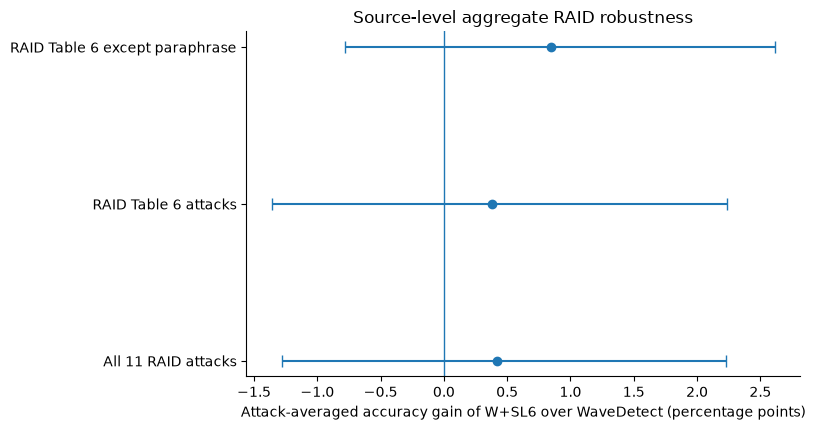

In [19]:
# ============================================================
# ATTACK-AVERAGED ROBUSTNESS:
# W+SL6 vs WaveDetect
#
# Primary:
#   all 11 RAID attacks
#
# Sensitivity:
#   the 6 attacks overlapping RAID Table 6,
#   and the same 6 excluding paraphrase.
#
# Bootstrap unit = source, NOT source x attack.
# ============================================================

from scipy.stats import binomtest

PRIMARY_ATTACKS = ATTACKS

RAID6_ATTACKS = [
    "paraphrase",
    "synonym",
    "perplexity_misspelling",
    "homoglyph",
    "whitespace",
    "article_deletion",
]

RAID6_NO_PARAPHRASE = [
    "synonym",
    "perplexity_misspelling",
    "homoglyph",
    "whitespace",
    "article_deletion",
]


def source_condition_accuracy(pred_df, method, attacks):
    """
    Return matrix:
        rows    = source
        columns = attack
        values  = mean correctness over matched
                  human + machine example for that condition.
    """

    z = pred_df[
        pred_df["method"].eq(method)
        & pred_df["condition"].isin(attacks)
    ].copy()

    # Each source-condition has exactly:
    #   one human negative
    #   one machine positive.
    per_condition = (
        z.groupby(
            ["prompt_id", "condition"]
        )["correct"]
        .mean()
        .unstack("condition")
    )

    # Strict complete support.
    per_condition = per_condition[
        attacks
    ].dropna()

    return per_condition


def attack_average_test(attacks, label, n_boot=100_000, seed=18181):

    W = source_condition_accuracy(
        pred,
        "WaveDetect",
        attacks,
    )

    WS = source_condition_accuracy(
        pred,
        "W+SL6",
        attacks,
    )

    common = W.index.intersection(
        WS.index
    )

    W = W.loc[common]
    WS = WS.loc[common]

    # Equal weight for every attack within each source.
    W_avg = W.mean(axis=1)
    WS_avg = WS.mean(axis=1)

    d = (
        WS_avg - W_avg
    ).to_numpy(float)

    rng = np.random.default_rng(seed)

    boot_idx = rng.integers(
        0,
        len(d),
        size=(n_boot, len(d)),
    )

    boot_mean = d[boot_idx].mean(axis=1)

    ci_lo, ci_hi = np.quantile(
        boot_mean,
        [0.025, 0.975],
    )

    positive = int((d > 0).sum())
    negative = int((d < 0).sum())
    ties = int((d == 0).sum())

    if positive + negative:
        sign_p = binomtest(
            positive,
            positive + negative,
            p=0.5,
            alternative="two-sided",
        ).pvalue
    else:
        sign_p = 1.0

    return {
        "attack_set": label,
        "n_attacks": len(attacks),
        "n_sources": len(d),

        "WaveDetect_mean_accuracy":
            W_avg.mean(),

        "W+SL6_mean_accuracy":
            WS_avg.mean(),

        "mean_gain":
            d.mean(),

        "median_gain":
            np.median(d),

        "ci95_lo":
            ci_lo,

        "ci95_hi":
            ci_hi,

        "positive_sources":
            positive,

        "negative_sources":
            negative,

        "ties":
            ties,

        "positive_fraction_nonties":
            (
                positive /
                (positive + negative)
                if positive + negative
                else np.nan
            ),

        "exact_sign_p":
            sign_p,
    }


robustness_rows = [
    attack_average_test(
        PRIMARY_ATTACKS,
        "All 11 RAID attacks",
        seed=18181,
    ),

    attack_average_test(
        RAID6_ATTACKS,
        "RAID Table 6 attacks",
        seed=18182,
    ),

    attack_average_test(
        RAID6_NO_PARAPHRASE,
        "RAID Table 6 except paraphrase",
        seed=18183,
    ),
]

robustness = pd.DataFrame(
    robustness_rows
)

display(robustness)

robustness.to_csv(
    RESULTS
    / "raid_scaled_attack_averaged_robustness.csv",
    index=False,
)


# ------------------------------------------------------------
# Pretty percentage-point readout
# ------------------------------------------------------------

pretty = robustness.copy()

for c in [
    "WaveDetect_mean_accuracy",
    "W+SL6_mean_accuracy",
    "mean_gain",
    "median_gain",
    "ci95_lo",
    "ci95_hi",
]:
    pretty[c] *= 100

print(
    "\n=== ATTACK-AVERAGED "
    "W+SL6 vs WAVDETECT ==="
)

display(
    pretty[
        [
            "attack_set",
            "n_attacks",
            "n_sources",
            "WaveDetect_mean_accuracy",
            "W+SL6_mean_accuracy",
            "mean_gain",
            "ci95_lo",
            "ci95_hi",
            "positive_sources",
            "negative_sources",
            "ties",
            "positive_fraction_nonties",
            "exact_sign_p",
        ]
    ]
)


# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.2, 4.4)
)

y = np.arange(
    len(pretty)
)

m = pretty["mean_gain"].to_numpy()

lo = (
    pretty["mean_gain"]
    - pretty["ci95_lo"]
).to_numpy()

hi = (
    pretty["ci95_hi"]
    - pretty["mean_gain"]
).to_numpy()

ax.errorbar(
    m,
    y,
    xerr=np.vstack([lo, hi]),
    fmt="o",
    capsize=4,
)

ax.axvline(
    0,
    linewidth=1,
)

ax.set_yticks(y)

ax.set_yticklabels(
    pretty["attack_set"]
)

ax.set_xlabel(
    "Attack-averaged accuracy gain "
    "of W+SL6 over WaveDetect "
    "(percentage points)"
)

ax.set_title(
    "Source-level aggregate RAID robustness"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

fig.savefig(
    FIGURES
    / "raid_scaled_attack_averaged_gain.pdf",
    bbox_inches="tight",
)

fig.savefig(
    FIGURES
    / "raid_scaled_attack_averaged_gain.png",
    dpi=200,
    bbox_inches="tight",
)

plt.show()